In [86]:
!if [ -d /content/ANN/.git ]; then git -C /content/ANN pull origin main; else git clone https://github.com/kondalokesh025-code/ANN.git /content/ANN; fi

From https://github.com/kondalokesh025-code/ANN
 * branch            main       -> FETCH_HEAD
Already up to date.


In [87]:
import sys
import importlib
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

repo_path = Path("/content/ANN")
sys.path.insert(0, str(repo_path))
importlib.invalidate_caches()

from src.data_loader import load_batches
from src.preprocessing import prepare_data
from src.model import Model

In [88]:
from google.colab import drive

drive_root = Path("/content/gdrive")

if not (drive_root / "MyDrive").exists():
    drive.mount("/content/gdrive")

drive_root = Path("/content/gdrive/MyDrive")

data_path = drive_root / "ANN-data"
save_dir = drive_root / "ANN-models"

save_dir.mkdir(parents=True, exist_ok=True)

print("Dataset exists:", data_path.exists())
print("Save directory:", save_dir)

Dataset exists: True
Save directory: /content/gdrive/MyDrive/ANN-models


In [89]:
batches = load_batches(data_path)
data = prepare_data(batches)

for name, value in data.items():
    if name.startswith("X_"):
        print(name, value.shape)

X_train torch.Size([5933, 128])
X_val torch.Size([3613, 128])
X_test_8 torch.Size([294, 128])
X_test_9 torch.Size([470, 128])
X_test_10 torch.Size([3600, 128])


In [90]:
model = Model()

loss_func = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

train_loader = data["train_loader"]
val_loader = data["val_loader"]

In [91]:
history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

best_val_loss = float("inf")
best_epoch = 0
num_epochs = 20

for epoch in range(num_epochs):

    model.train()
    total_loss = 0
    total_samples = 0

    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()

        pred = model(batch_x)
        loss = loss_func(pred, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch_x.size(0)
        total_samples += batch_x.size(0)

    avg_train_loss = total_loss / total_samples
    history["train_loss"].append(avg_train_loss)

    model.eval()

    val_total_loss = 0
    val_total_samples = 0
    correct = 0

    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            pred = model(batch_x)
            loss = loss_func(pred, batch_y)

            val_total_loss += loss.item() * batch_x.size(0)
            val_total_samples += batch_x.size(0)

            predictions = pred.argmax(dim=1)
            correct += (predictions == batch_y).sum().item()

    avg_val_loss = val_total_loss / val_total_samples
    val_accuracy = correct / val_total_samples * 100

    history["val_loss"].append(avg_val_loss)
    history["val_accuracy"].append(val_accuracy)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            save_dir / "baseline_best.pth"
        )

    print(
        f"Epoch: {epoch + 1} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch: 1 | Train Loss: 0.8117 | Val Loss: 0.8917 | Val Accuracy: 74.07%
Epoch: 2 | Train Loss: 0.2950 | Val Loss: 0.8176 | Val Accuracy: 66.92%
Epoch: 3 | Train Loss: 0.1601 | Val Loss: 0.7176 | Val Accuracy: 76.75%
Epoch: 4 | Train Loss: 0.1058 | Val Loss: 0.7446 | Val Accuracy: 75.31%
Epoch: 5 | Train Loss: 0.0797 | Val Loss: 0.7550 | Val Accuracy: 72.71%
Epoch: 6 | Train Loss: 0.0658 | Val Loss: 0.6875 | Val Accuracy: 75.15%
Epoch: 7 | Train Loss: 0.0556 | Val Loss: 0.6370 | Val Accuracy: 79.19%
Epoch: 8 | Train Loss: 0.0496 | Val Loss: 0.6356 | Val Accuracy: 78.85%
Epoch: 9 | Train Loss: 0.0435 | Val Loss: 0.7164 | Val Accuracy: 74.59%
Epoch: 10 | Train Loss: 0.0394 | Val Loss: 0.6545 | Val Accuracy: 77.94%
Epoch: 11 | Train Loss: 0.0360 | Val Loss: 0.7802 | Val Accuracy: 75.01%
Epoch: 12 | Train Loss: 0.0342 | Val Loss: 0.6046 | Val Accuracy: 80.32%
Epoch: 13 | Train Loss: 0.0322 | Val Loss: 0.5343 | Val Accuracy: 82.95%
Epoch: 14 | Train Loss: 0.0297 | Val Loss: 0.7047 | Val Accu

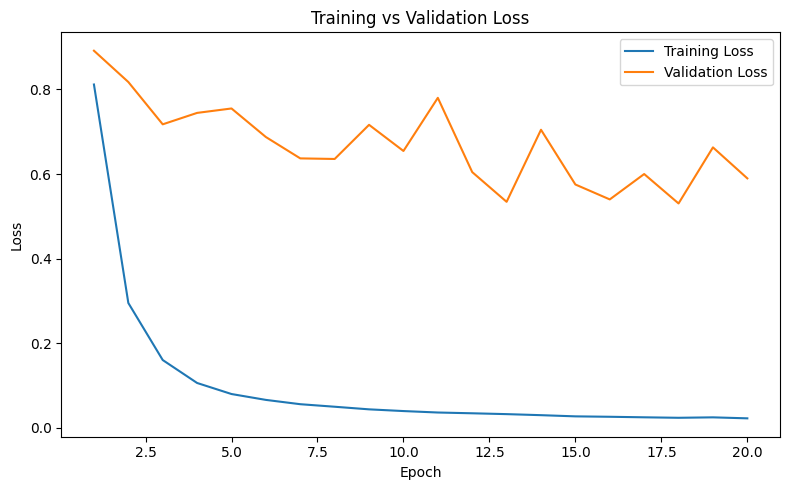

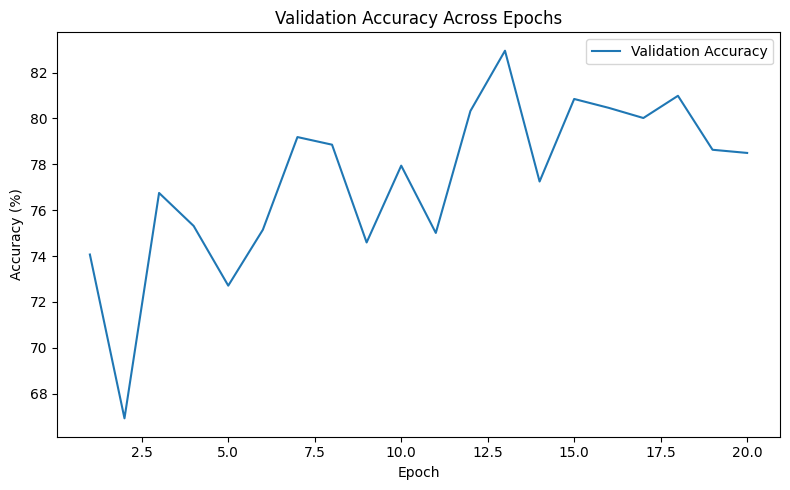

In [92]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Validation Accuracy Across Epochs")
plt.legend()
plt.tight_layout()
plt.show()

In [93]:
model.load_state_dict(
    torch.load(
        save_dir / "baseline_best.pth",
        map_location="cpu",
        weights_only=True
    )
)

model.eval()

joblib.dump(
    data["scaler"],
    save_dir / "scaler.pkl"
)

print("Best model and scaler saved successfully.")

Best model and scaler saved successfully.


In [94]:
class_names = [
    "Ethanol",
    "Ethylene",
    "Ammonia",
    "Acetaldehyde",
    "Acetone",
    "Toluene"
]

all_preds = []
all_labels = []

with torch.no_grad():
    for batch_x, batch_y in val_loader:
        predictions = model(batch_x).argmax(dim=1)

        all_preds.extend(predictions.numpy())
        all_labels.extend(batch_y.numpy())

print(
    classification_report(
        all_labels,
        all_preds,
        labels=list(range(6)),
        target_names=class_names,
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Ethanol      0.757     1.000     0.862       649
    Ethylene      0.738     0.998     0.849       662
     Ammonia      0.804     0.822     0.813       360
Acetaldehyde      0.964     0.392     0.558       744
     Acetone      0.798     0.998     0.887       630
     Toluene      0.995     0.702     0.824       568

    accuracy                          0.810      3613
   macro avg      0.843     0.819     0.799      3613
weighted avg      0.845     0.810     0.790      3613



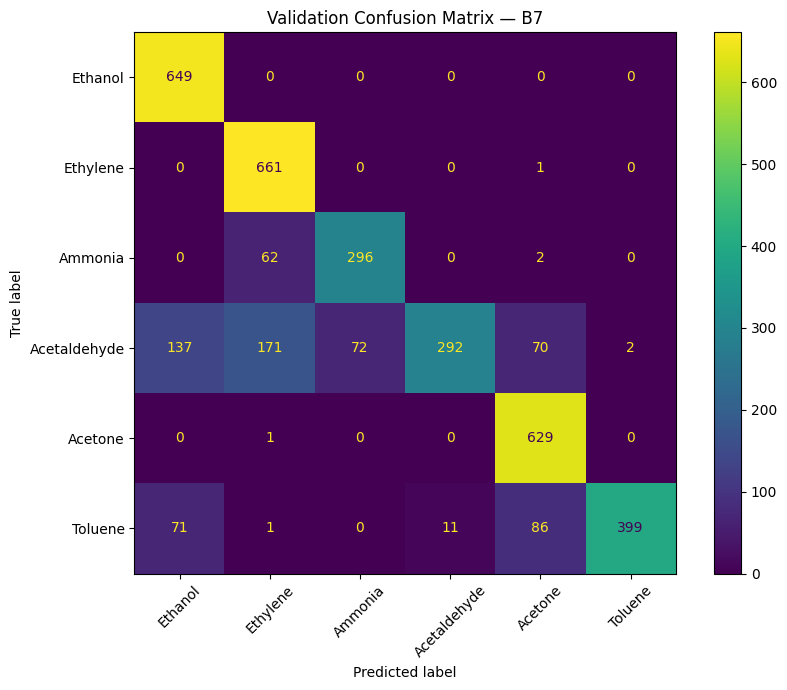

In [95]:
cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(6))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))
display.plot(ax=ax, xticks_rotation=45)
ax.set_title("Validation Confusion Matrix — B7")
plt.tight_layout()
plt.show()

In [97]:
for file in save_dir.iterdir():
    if file.is_file():
        print(file.name)

baseline_best.pth
scaler.pkl
